# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Михальчук Антон Євгенійович'
LIST_NUMBER  = 13

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 13: Вінниця, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_вінниця


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # живий запит: міряємо приріст кешу osmnx (байти з мережі) і час
    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g


In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 113.1 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 17996 | ребер 52316


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.026,0.04
heritage,знімок,159,0.0,0.073,0.042
stations,знімок,4,0.0,0.049,0.032
amenities,знімок,426,0.0,0.097,0.041
мережа walk,знімок,70312,0.0,3.616,0.126


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
from shapely.geometry import Point

has_hist = heritage['historic'].notna()
has_tour = heritage['tourism'].isin(TOURISM_OK)
has_name = heritage['name'].notna()
mask = has_hist | has_tour                      # об'єднання сімейств, а не перетин

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()), '(historic %d, tourism %d, обидва %d)'
      % (has_hist.sum(), has_tour.sum(), (has_hist & has_tour).sum()))
print('з них мають name       :', int((mask & has_name).sum()))
print()
print('ВІДКИНУТО без назви:', int((mask & ~has_name).sum()))
dropped = heritage[mask & ~has_name]
print(dropped['historic'].fillna('—').value_counts().to_dict(), dropped['tourism'].fillna('—').value_counts().to_dict())

cand = heritage[mask & has_name].reset_index(drop=True)

# Рішення: 33 військові експонати (літаки, гармати, ракета) — це експозиція
# просто неба Музею Повітряних Сил, а не окремі пам'ятки. Сам музей уже є
# серед кандидатів як полігон, тож експонати прибираємо як його дублікати.
EXHIBIT = ['aircraft', 'cannon', 'missile']
is_ex = cand['historic'].isin(EXHIBIT)
museum_af = cand.loc[cand['name'] == 'Музей Повітряних Сил', 'geometry'].iloc[0]
inside = cand.loc[is_ex, 'geometry'].within(museum_af)
pm = cand[is_ex].to_crs(32635).geometry.representative_point()
print()
print('експонатів прибрано:', int(is_ex.sum()), cand.loc[is_ex, 'historic'].value_counts().to_dict(),
      '| усередині полігона Музею ПС: %d з %d' % (inside.sum(), len(inside)),
      '| розкид %.0f × %.0f м' % (pm.x.max() - pm.x.min(), pm.y.max() - pm.y.min()))
cand = cand[~is_ex].reset_index(drop=True)
print('кандидатів:', len(cand))

усього у шарі heritage : 159
підходять за тегами    : 159 (historic 101, tourism 59, обидва 1)
з них мають name       : 138

ВІДКИНУТО без назви: 21
{'—': 8, 'memorial': 6, 'building': 3, 'wayside_cross': 2, 'monument': 1, 'tomb': 1} {'—': 13, 'artwork': 5, 'museum': 2, 'viewpoint': 1}

експонатів прибрано: 33 {'aircraft': 23, 'cannon': 9, 'missile': 1} | усередині полігона Музею ПС: 33 з 33 | розкид 108 × 84 м
кандидатів: 105


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          42
building           4
yes                4
manor              2
monument           1
castle             1
boundary_stone     1

=== tourism ===
tourism
artwork       27
museum        13
attraction     8
viewpoint      3

типи геометрії: {'Point': 86, 'Polygon': 17, 'LineString': 2}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in ('wikidata', 'wikipedia') if c in cand.columns]
name_cols = [c for c in cand.columns if c.startswith('name:')]
cand['wiki']   = cand[wiki_cols].notna().any(axis=1).astype(int)
cand['n_lang'] = cand[name_cols].notna().sum(axis=1)
cand['museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)

# Ваги: зовнішнє визнання (стаття) найсильніше; переклади назви — що шукають
# іноземці; музей — місце, призначене для відвідування. Площу не беремо:
# великим буває і склад, а в 88 зі 105 кандидатів (точки) площа = 0;
# площа — окремий наївний критерій для порівняння.
W_RAW = {'wiki': 4, 'n_lang': 3, 'museum': 2}          # пропорції 4 : 3 : 2
W = {k: v / sum(W_RAW.values()) for k, v in W_RAW.items()}   # сума ваг = 1
print('ваги:', {k: round(v, 3) for k, v in W.items()})
cand['score'] = sum(w * cand[c].rank(pct=True) for c, w in W.items())

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають переклади назви:', int((cand['n_lang'] > 0).sum()), '| медіана мов:', cand['n_lang'].median())
print('музеїв/галерей:', int(cand['museum'].sum()))

ваги: {'wiki': 0.444, 'n_lang': 0.333, 'museum': 0.222}
кандидатів   : 105
мають wiki   : 22
мають переклади назви: 103 | медіана мов: 1.0
музеїв/галерей: 13


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.sort_values(['score', 'n_lang', 'name'], ascending=[False, False, True]).head(N_LARGE).reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.sort_values(['area_m2', 'name'], ascending=[False, True]).head(N_SMALL).reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'score': top10['score'].round(3).values,
                      'за площею': list(top_naive['name']),
                      'площа, м²': top_naive['area_m2'].round(0).values}))

перетин: 4 з 10


,за вашим критерієм,score,за площею,"площа, м²"
0,Музей моделей транспорту,0.933,Музей Повітряних Сил,17089.0
1,Національний музей-садиба М. І. Пирогова,0.933,Національний музей-садиба М. І. Пирогова,887.0
2,Обласний краєзнавчий музей,0.933,"Фонтан ""Рошен""",614.0
3,Музей М. М. Коцюбинського,0.895,Спасо-Преображенський кафедральний собор,510.0
4,Обласний художній музей,0.895,Садиба Львовича,499.0
5,Синагога Ліфшиця,0.822,Дача Майка,445.0
6,Спасо-Преображенський кафедральний собор,0.822,Пам'ятник загиблим 14 липня 2022,397.0
7,"Фонтан ""Рошен""",0.822,Синагога Ліфшиця,372.0
8,Василеві Стусу,0.784,Маєток Болеслава Лещинського,345.0
9,Водонапірна вежа,0.784,Будинок Натана Альтмана,318.0


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score)
print('пар ближче 60 м у топ-30:', len(pairs))
for i, j, d in pairs:
    print('  %5.1f м | %s  <->  %s' % (d, top_score.loc[i, 'name'], top_score.loc[j, 'name']))
# перевірка, що функція працює: на всіх кандидатах пар має бути більше
print('для контролю, пар серед усіх кандидатів:', len(close_pairs(cand)))

# Рішення: «Братська могила розстріляних євреїв» двічі за 40 м — дублікат
# одного об'єкта в OSM, лишаємо запис з вищим score. Решта пар — різні
# об'єкти, що стоять поруч у центрі (музеї, собор, пам'ятник), їх лишаємо.
dup = cand[cand['name'] == 'Братська могила розстріляних євреїв'].sort_values('score', ascending=False)
cand = cand.drop(index=dup.index[1:]).reset_index(drop=True)
print()
print('прибрано дублікатів могили:', len(dup) - 1, '| кандидатів:', len(cand))

top_score = cand.sort_values(['score', 'n_lang', 'name'], ascending=[False, False, True]).head(N_LARGE).reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.sort_values(['area_m2', 'name'], ascending=[False, True]).head(N_SMALL).reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин після чистки: %d з %d' % (overlap, N_SMALL))
print('пар ближче 60 м у топ-30 після чистки:', len(close_pairs(top_score)))

пар ближче 60 м у топ-30: 6
   35.3 м | Обласний художній музей  <->  Тарасові Шевченку
   36.8 м | Обласний художній музей  <->  Спасо-Преображенський кафедральний собор
   38.9 м | Музей моделей транспорту  <->  Синагога Ліфшиця
   40.0 м | Братська могила розстріляних євреїв  <->  Братська могила розстріляних євреїв
   40.6 м | Обласний краєзнавчий музей  <->  Тарасові Шевченку
   48.9 м | Обласний краєзнавчий музей  <->  Обласний художній музей
для контролю, пар серед усіх кандидатів: 26

прибрано дублікатів могили: 1 | кандидатів: 104
перетин після чистки: 4 з 10
пар ближче 60 м у топ-30 після чистки: 5


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 4
                 name  railway       building
0                5 км     halt            NaN
1             Вінниця  station            NaN
2    Вінниця-Вантажна     halt            NaN
3  Залізничний вокзал      NaN  train_station


In [16]:
# Рішення: будівля вокзалу (building=train_station), а не точка railway=station
# за 42 м від неї — пішохід стартує від будівлі.
station = stations[stations['building'] == 'train_station'].head(1)
print('старт:', station['name'].iloc[0], '|', station.geometry.iloc[0].geom_type)

старт: Залізничний вокзал | Polygon


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 17996 вузлів, 51796 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    print('%s: точок %d, різних вузлів %d | точка→вузол: медіана %.0f м, максимум %.0f м'
          % (label, n_pts, n_nodes, np.median(dist), np.max(dist)))
    if n_nodes < n_pts:
        groups = collections.defaultdict(list)
        for name, nd in zip(points['name'], ids):
            groups[nd].append(name)
        for nd, names in groups.items():
            if len(names) > 1:
                print('  ЗЛИПЛИСЬ на вузлі %s: %s' % (nd, ' | '.join(names)))

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    ok = np.isfinite(D) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 10 | точка→вузол: медіана 22 м, максимум 64 м
  ЗЛИПЛИСЬ на вузлі 9909099954: Обласний краєзнавчий музей | Обласний художній музей


матриця за 0.397 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.16


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    tour, left = [0], set(range(1, len(D)))
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j])
        tour.append(nxt); left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best, best_len = list(tour), tour_length(D, tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for k in range(i + 1, len(best) - 1):
                cand_t = best[:i] + best[i:k + 1][::-1] + best[k + 1:]
                L = tour_length(D, cand_t)      # повна довжина: D може бути несиметричною
                if L < best_len - 1e-9:
                    best, best_len, improved = cand_t, L, True
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,19819,1.38
2-opt,19621,0.37
Held-Karp (точний),19549,0.00



оптимальний порядок:
   0. СТАРТ: Залізничний вокзал
   1. Музей М. М. Коцюбинського
   2. Спасо-Преображенський кафедральний собор
   3. Водонапірна вежа
   4. Музей моделей транспорту
   5. Синагога Ліфшиця
   6. Василеві Стусу
   7. Національний музей-садиба М. І. Пирогова
   8. Обласний художній музей
   9. Обласний краєзнавчий музей
  10. Фонтан "Рошен"
  11. СТАРТ: Залізничний вокзал

довжина: 19.55 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'точок': n, 'клітин': '%.1e' % cells,
                 'пам’ять, ГБ': round(cells * 8 / 1e9, 3),
                 'операцій': '%.1e' % (cells * (n - 1))})
display(pd.DataFrame(rows).set_index('точок'))

,клітин,"пам’ять, ГБ",операцій
точок,,,
11,1.0e+04,0.000,1.0e+05
16,4.9e+05,0.004,7.4e+06
21,2.1e+07,0.168,4.2e+08
26,8.4e+08,6.711,2.1e+10
31,3.2e+10,257.698,9.7e+11


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 29 | точка→вузол: медіана 22 м, максимум 93 м
  ЗЛИПЛИСЬ на вузлі 9909099954: Обласний краєзнавчий музей | Обласний художній музей | Тарасові Шевченку


коефіцієнт обходу: 1.19
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    36045 м
2-opt            :    32336 м  за 0.010 с  (коротше на 10.3%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів 104 у 64 комірках; половина — у 16 комірках


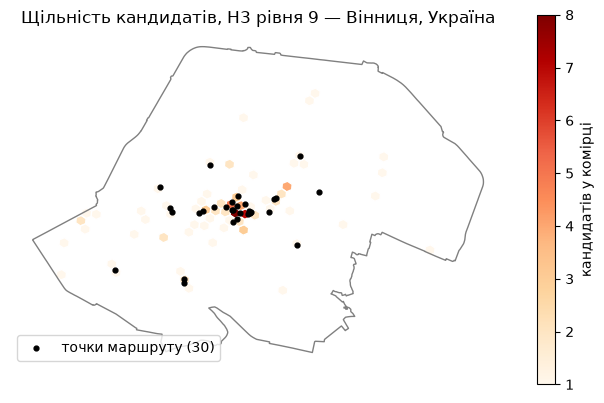

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in cand.geometry.representative_point()]
dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame({'n': dens.values},
                         geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])
                                   for c in dens.index], crs='EPSG:4326')
half = int(np.searchsorted(dens.cumsum().values, len(cand) / 2) + 1)
print('кандидатів %d у %d комірках; половина — у %d комірках' % (len(cand), len(dens), half))

fig, ax = plt.subplots(figsize=(8, 8))
boundary.boundary.plot(ax=ax, color='grey', linewidth=1)
hexes.plot(ax=ax, column='n', cmap='OrRd', legend=True, edgecolor='white',
           legend_kwds={'label': 'кандидатів у комірці', 'shrink': 0.6})
pts30.plot(ax=ax, color='black', markersize=12, label='точки маршруту (30)')
ax.set_title('Щільність кандидатів, H3 рівня 9 — ' + CITY)
ax.legend(loc='lower left'); ax.set_axis_off()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
pts_m = pts30.to_crs(32635)
am_m = amenities.to_crs(32635)[['name', 'amenity', 'geometry']]
near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='відстань_м',
                         lsuffix='точка', rsuffix='заклад')
near = near[~near.index.duplicated()]          # однакові відстані дають дублікати рядків
tbl = near[['name_точка', 'amenity', 'name_заклад', 'відстань_м']].round({'відстань_м': 0})
display(tbl)
print('медіана до найближчого закладу: %.0f м, максимум %.0f м'
      % (tbl['відстань_м'].median(), tbl['відстань_м'].max()))

,name_точка,amenity,name_заклад,відстань_м
0,СТАРТ: Залізничний вокзал,cafe,O`Cake,115.0
1,Музей моделей транспорту,cafe,Fluid,37.0
2,Національний музей-садиба М. І. Пирогова,toilets,NaN,134.0
3,Обласний краєзнавчий музей,drinking_water,NaN,76.0
4,Музей М. М. Коцюбинського,restaurant,Аристократ,24.0
5,Обласний художній музей,drinking_water,NaN,27.0
6,Синагога Ліфшиця,cafe,Fluid,71.0
7,Спасо-Преображенський кафедральний собор,drinking_water,NaN,24.0
8,"Фонтан ""Рошен""",toilets,NaN,118.0
9,Василеві Стусу,cafe,Плеяда,131.0


медіана до найближчого закладу: 102 м, максимум 766 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

order = ex10                                  # оптимальний маршрут малої задачі
road_line = route_coords(order, ids10)
straight_line = [(pts10.geometry.iloc[i].y, pts10.geometry.iloc[i].x) for i in order]

centre = [pts10.geometry.y.mean(), pts10.geometry.x.mean()]
fmap = folium.Map(location=centre, zoom_start=14, tiles=None)
folium.TileLayer(tiles=BASEMAP.build_url(), attr=BASEMAP.html_attribution + ' | Дані © OpenStreetMap contributors, ODbL',
                 name='Esri WorldGrayCanvas').add_to(fmap)
folium.PolyLine(road_line, color='#1a7f5a', weight=5, opacity=0.85,
                tooltip='маршрут по ребрах графа: %.2f км' % (L_opt / 1000)).add_to(fmap)
folium.PolyLine(straight_line, color='#c0392b', weight=2, dash_array='6 6',
                tooltip='прямі відрізки: %.2f км' % (tour_length(E10, order) / 1000)).add_to(fmap)
for step, i in enumerate(order[:-1]):
    p = pts10.geometry.iloc[i]
    folium.Marker([p.y, p.x], tooltip='%d. %s' % (step, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="background:%s;color:#fff;border-radius:50%%;'
                                           'width:24px;height:24px;text-align:center;line-height:24px;'
                                           'font:bold 12px sans-serif">%s</div>'
                                           % ('#000' if i == 0 else '#1a7f5a', 'В' if i == 0 else step))).add_to(fmap)
lats = [c[0] for c in road_line + straight_line]; lons = [c[1] for c in road_line + straight_line]
fmap.fit_bounds([[min(lats), min(lons)], [max(lats), max(lons)]], padding=(20, 20))   # увесь маршрут у кадрі
fmap.save('lr5_маршрут.html')
print('по ребрах %.2f км, по прямій %.2f км' % (L_opt / 1000, tour_length(E10, order) / 1000))
fmap

по ребрах 19.55 км, по прямій 16.35 км


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.0 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [31]:
REPORT = '''
Місто: Вінниця (варіант 13). Дані © OpenStreetMap contributors, ліцензія ODbL.
Дані отримано живим запитом 05.11.2026. Головний сервер Overpass відповів 502 (перевантажений),
тому пішохідну мережу завантажено через дзеркало overpass.private.coffee: 7,7 МБ мережею за 84,5 с.
Повторне читання знімка мережі — 0,13 с, тобто приблизно в 650 разів швидше, і 0 МБ мережею.
Час живих запитів для малих шарів не зафіксовано: перший запуск упав на мережі до виводу таблиці.

1. У шарі heritage 159 об'єктів: historic 101, tourism зі списку 59, обидва теги лише 1, тому беремо
   об'єднання. Без name відкинуто 21 (серед них 2 музеї, 5 artwork, 1 viewpoint, 6 меморіалів),
   бо безіменну точку не можна дати в маршрут. Ще 33 об'єкти (23 літаки, 9 гармат, 1 ракета) прибрано:
   усі 33 лежать усередині полігона «Музею Повітряних Сил», тобто це експонати одного музею, а не
   окремі пам'ятки. Без пояснень замовнику такий фільтр не віддав би: він мовчки викидає два музеї
   без назви і цілу експозицію.

2. Сигнали: wiki (є wikidata/wikipedia) — 0.444, n_lang (скільки мов у name:*) — 0.333,
   museum (tourism = museum/gallery) — 0.222; пропорції 4 : 3 : 2, сума 1. Кожен сигнал зведено
   до шкали 0..1 через rank(pct=True). Стаття — найсильніший сигнал, бо це визнання поза OSM;
   переклади назви показують, що об'єкт шукають іноземці; музей призначений для відвідування.
   Площу не брав: у 87 зі 104 кандидатів (точки й лінії) вона 0, а великим буває і склад.

3. Збіглося 4 з 10 (садиба Пирогова, собор, фонтан «Рошен», синагога Ліфшиця). Обидва списки —
   з тих самих даних без помилок у коді, але різні. «Найкращі» не є властивістю даних: відповідь
   задає критерій, який обрав аналітик. За площею першим іде Музей Повітряних Сил (17 089 м²) лише
   тому, що його полігон — це майданчик з літаками.

4. Коефіцієнт обходу: 1,16 на 10 точках і 1,19 на 30 точках, трохи нижче типових 1,2–1,6.
   Пішохідна мережа в центрі щільна, а більшість пам'яток зосереджені в центрі (див. H3), тож
   пішки майже по прямій. Річка Південний Буг віддалі не роздуває: недосяжних пар 0.
   Асиметрія 0 м, бо пішохідні ребра двосторонні.

5. Найближчий сусід гірший за точний розв'язок (19 549 м) на 1,38 % (19 819 м), 2-opt — на 0,37 %
   (19 621 м). На 10 точках жадібний метод майже не помиляється. А на 30 точках 2-opt скоротив
   маршрут найближчого сусіда на 10,3 % (36 045 → 32 336 м): похибка жадібного методу росте з n.

6. Таблиця Held–Karp на 31 точку має 2^30 · 30 ≈ 3,2·10^10 клітин, тобто 258 ГБ при 8 байтах
   на клітину. Вона не вміщається в пам'ять ноутбука, а не просто рахується довго.

7. Що виявилось неправильним у даних:
   - 21 об'єкт без назви, серед них 2 музеї — відкинув;
   - 33 експонати Музею ПС внесено як окремі «історичні» об'єкти — прибрав як частину музею;
   - «Братська могила розстріляних євреїв» двічі за 40 м — лишив один запис;
   - Обласний краєзнавчий і Обласний художній музеї (і пам'ятник Шевченку на 30 точках) сіли
     на один вузол графа: віддаль між ними 0, маршрут обходить їх безплатно. Вони стоять за
     35–49 м один від одного, тож різні об'єкти лишив, але число різних вузлів — 10 з 11 і 29 з 31.
   Інші пари ближче 60 м (музеї, собор, пам'ятник у центрі) — різні об'єкти, лишив.

H3: 104 кандидати в 64 комірках рівня 9, половина — лише в 16. Пам'ятки скупчені в центрі,
тому маршрут має щільне ядро, а довжину роздувають кілька віддалених точок (садиба Пирогова).
Найближчий заклад: медіана 102 м, максимум 766 м.
Карта: маршрут по ребрах 19,55 км проти 16,35 км прямими відрізками.

Висновок, якого не було в завданні: на 10 точках вибір алгоритму змінює довжину лише на 1,4 %,
а вибір критерію «найкращих» міняє 6 об'єктів із 10. Для замовника критерій важить більше
за алгоритм маршруту.

Декларація про використання ШІ:
Користувався Claude (Anthropic) у Claude Code: пояснення теорії, написання коду кроків 1–9
і чернетка цього звіту. Рішення приймав сам: правило відбору, прибрати експонати Музею ПС,
прибрати дублікат могили, ваги 4 : 3 : 2 без площі, старт від будівлі вокзалу. Перевірка:
assert-и структури маршруту (2-opt ≤ найближчий сусід, точний ≤ 2-opt); check_snap;
перевірка, що всі 33 експонати лежать усередині полігона музею; коефіцієнт обходу звірено
з діапазоном 1,2–1,6; усі метричні обчислення в EPSG:32635; карта переглянута оком:
маршрут іде вулицями, прямі відрізки — ні.
'''
print(REPORT)


Місто: Вінниця (варіант 13). Дані © OpenStreetMap contributors, ліцензія ODbL.
Дані отримано живим запитом 05.11.2026. Головний сервер Overpass відповів 502 (перевантажений),
тому пішохідну мережу завантажено через дзеркало overpass.private.coffee: 7,7 МБ мережею за 84,5 с.
Повторне читання знімка мережі — 0,13 с, тобто приблизно в 650 разів швидше, і 0 МБ мережею.
Час живих запитів для малих шарів не зафіксовано: перший запуск упав на мережі до виводу таблиці.

1. У шарі heritage 159 об'єктів: historic 101, tourism зі списку 59, обидва теги лише 1, тому беремо
   об'єднання. Без name відкинуто 21 (серед них 2 музеї, 5 artwork, 1 viewpoint, 6 меморіалів),
   бо безіменну точку не можна дати в маршрут. Ще 33 об'єкти (23 літаки, 9 гармат, 1 ракета) прибрано:
   усі 33 лежать усередині полігона «Музею Повітряних Сил», тобто це експонати одного музею, а не
   окремі пам'ятки. Без пояснень замовнику такий фільтр не віддав би: він мовчки викидає два музеї
   без назви і цілу експозицію.

2.